# PS1 Solution 

**Group:** Giovanni Cecchi, Zoe Di Lieto, David Herskovits, Lorenzo Morandi, Jakub Przewoski


## Step 1: Scrape the top-500 paid apps table

The table is in the server response itself, not built by JavaScript, so `requests` is enough. The table markup is HTML-escaped inside the page (`&lt;table&gt;`), so we run `html.unescape()` before handing it to BeautifulSoup.

In [47]:
# only run this if haven't installed it before
# pip install google-play-scraper

In [1]:
import html
import pandas as pd
import requests
import matplotlib.pyplot as plt
import numpy as np
from bs4 import BeautifulSoup
from google_play_scraper import app

In [2]:
URL = "https://sites.google.com/view/francescodecarolis/data/apps-dataset"

response = requests.get(URL)
response.raise_for_status()

soup = BeautifulSoup(html.unescape(response.text), "html.parser")
tables = soup.find_all("table")
print("tables on page:", len(tables))

tables on page: 1


In [3]:
rows = tables[0].find_all("tr")
header = [cell.get_text(strip=True) for cell in rows[0].find_all(["th", "td"])]
print("header:", header)
assert header == ["Rank", "App", "Developer", "App id"]

records = []
for row in rows[1:]:
    cells = [td.get_text(strip=True) for td in row.find_all("td")]
    assert len(cells) == 4, cells  # stop loudly on any malformed row
    records.append(cells)

top500 = pd.DataFrame(records, columns=["rank", "name", "developer", "app_id"])
top500["rank"] = top500["rank"].astype(int)
top500.head()

header: ['Rank', 'App', 'Developer', 'App id']


,rank,name,developer,app_id
0,1,Minecraft,Mojang,com.mojang.minecraftpe
1,2,Bloons TD 6,ninja kiwi,com.ninjakiwi.bloonstd6
2,3,Bad North: Jotunn Edition,Raw Fury,com.PlausibleConcept.BadNorthFull
3,4,Evertale,ZigZaGame Inc.,com.zigzagame.evertale
4,5,Geometry Dash,RobTop Games,com.robtopx.geometryjump


### Checks on the scraped table

In [5]:
# Row count and ranks
print("rows:", len(top500))
print("duplicate ranks:", top500["rank"].duplicated().sum())
print("ranks are exactly 1..500:", sorted(top500["rank"]) == list(range(1, 501)))

# Missing / empty cells
print("\nmissing or empty cells per column:")
print((top500.isna() | (top500.astype(str) == "")).sum())

# Duplicate app ids
dup_ids = top500[top500["app_id"].duplicated(keep=False)]
print("\nrows with a duplicated app_id:", len(dup_ids))
dup_ids

rows: 500
duplicate ranks: 0
ranks are exactly 1..500: True

missing or empty cells per column:
rank         0
name         0
developer    0
app_id       0
dtype: int64

rows with a duplicated app_id: 0


,rank,name,developer,app_id


In [6]:
top500.to_csv("output/top500_raw.csv", index=False)

### Combining datasets

Now we run the `app()` function from `google_play_scraper` on the dataset to acquire the individual characteristics of the apps.

In [4]:
# read in the saved dataset if not running previous code
top500 = pd.read_csv("output/top500_raw.csv")

In [9]:
# running the for loop 

#pre-allocated dictionary
play_res_json = [None] * 500
lost_counter = 0

# for loop collecting the results
for res in range(len(play_res_json)):
    try:
        result = app(top500.iloc[res,3])
        play_res_json[res] = result
    except Exception as e:
        lost_counter += 1
        play_res_json[res] = {"appId":top500.iloc[res,3], "drop_reason":f"{type(e).__name__}: {e}"}




In [10]:
print(f"We missed {lost_counter} observations")
play_res_df = pd.json_normalize(play_res_json)
play_res_df.to_csv("output/play_res.csv")

We missed 142 observations


In [ ]:
# play_res_df= pd.read_csv("output/play_res.csv")
print(play_res_df.isna().sum())
print(play_res_df["appId"].isna().sum())
# we don't miss any appId's so we can actually cleanly merge.

Unnamed: 0                    0
title                       143
description                 143
descriptionHTML             143
summary                     143
installs                    143
minInstalls                 143
realInstalls                143
score                       143
ratings                     143
reviews                     143
histogram                   143
price                       143
free                        143
currency                    143
sale                        143
saleTime                    500
originalPrice               500
saleText                    500
offersIAP                   143
inAppProductPrice           363
developer                   143
developerId                 143
developerEmail              143
developerWebsite            162
developerAddress            500
privacyPolicy               143
genre                       143
genreId                     143
categories                  143
icon                        143
headerIm

In [5]:
# joining the data
merged = top500.merge(play_res_df, how="left", left_on="app_id", right_on="appId")


In [ ]:
# dimensions check out
print(top500.shape)
print(play_res_df.shape)
print(merged.shape)
print(merged["price"].describe())
# number of 0-price apps
print(len(merged[merged["price"]==0]))
print(f'length of the dataset after dropping 0-price apps:{500-len(merged[merged["price"]==0])}')

# dropping 0-price apps
merged = merged[merged["price"]!=0]
merged.to_csv("output/merged.csv")

(500, 4)
(500, 47)
(500, 51)
count    357.000000
mean       5.234538
std        6.826116
min        0.000000
25%        1.990000
50%        3.990000
75%        5.990000
max       84.990000
Name: price, dtype: float64
27
length of the dataset after dropping 0-price apps:473


### Additional variables

Here we create additional variables from part 1.3

In [ ]:
# read in the merged dataset if not running previous code
merged = pd.read_csv("output/merged.csv", index_col=0)

(473, 51)

In [ ]:
# quantity = max(20 * reviews, minInstalls): installs are a lower bound, so they act as a floor
# np.fmax ignores NaN: an app with no reviews gets the floor; the 143 dropped apps stay empty
matched = merged["drop_reason"].isna()
upper_bounds = {
    1_000: 5_000,
    5_000: 10_000,
    10_000: 50_000,
    50_000: 100_000,
    100_000: 500_000,
    500_000: 1_000_000,
    1_000_000: 5_000_000,
    5_000_000: 10_000_000,
    10_000_000: 50_000_000,
    50_000_000: 100_000_000,
}

L = merged["minInstalls"]
U = L.map(upper_bounds)
merged["maxInstalls"] = U

midpoint = np.sqrt(L * U)

merged["install_midpoint"] = midpoint

#1
merged["quantity1"] = 20 * merged["reviews"]
#2
merged["quantity2"] = 20 * merged["ratings"]
#3
merged["quantity3"] = 30 * merged["ratings"]
#4
merged["quantity4"] = 0.5 * midpoint + 15 * merged["ratings"]

for i in range(1,5):
    # floor and ceiling binds variables
    merged[f"floor_binds{i}"] = (merged[f"quantity{i}"] <= merged["minInstalls"]).where(matched)
    merged[f"ceiling_binds{i}"] = (merged[f"quantity{i}"] >= merged["maxInstalls"]).where(matched)

    # setting quantity to ceiling if ceiling binds
    # no need to do it for the floor, because we have done it before.
    merged[f"quantity{i}"] = np.where(
    merged[f"ceiling_binds{i}"], merged["maxInstalls"], merged[f"quantity{i}"]
)
    merged[f"quantity{i}"] = np.where(
        merged[f"floor_binds{i}"], merged["minInstalls"], merged[f"quantity{i}"]
    )
    
    # printing results
    print("matched apps with quantity:", merged.loc[matched, f"quantity{i}"].notna().sum(), "/", matched.sum())
    print("dropped apps with quantity (should be 0):", merged.loc[~matched, f"quantity{i}"].notna().sum())
    print("floor binds for:", (merged[f"floor_binds{i}"] == True).sum(), "apps")
    print("ceiling binds for:", (merged[f"ceiling_binds{i}"] == True).sum(), "apps")




# checks
print("rows:", len(merged))
merged.to_csv("output/merged.csv")

matched apps with quantity: 330 / 330
dropped apps with quantity (should be 0): 0
floor binds for: 321 apps
ceiling binds for: 0 apps
matched apps with quantity: 330 / 330
dropped apps with quantity (should be 0): 0
floor binds for: 142 apps
ceiling binds for: 21 apps
matched apps with quantity: 330 / 330
dropped apps with quantity (should be 0): 0
floor binds for: 85 apps
ceiling binds for: 61 apps
matched apps with quantity: 330 / 330
dropped apps with quantity (should be 0): 0
floor binds for: 20 apps
ceiling binds for: 24 apps
rows: 473


In [48]:
matched = merged["drop_reason"].isna()

# map genreId -> parent group (genreId, not genre: "Sports" is both a game and an app genre)
group_map = {
    "TOOLS": "Tools & Personalization", "PERSONALIZATION": "Tools & Personalization",
    "PRODUCTIVITY": "Productivity & Business", "BUSINESS": "Productivity & Business",
    "EDUCATION": "Education & Reference", "BOOKS_AND_REFERENCE": "Education & Reference",
    "PHOTOGRAPHY": "Photo & Video", "VIDEO_PLAYERS": "Photo & Video",
    "HEALTH_AND_FITNESS": "Health & Fitness", "MEDICAL": "Health & Fitness",
    "MUSIC_AND_AUDIO": "Music & Audio",
    # games, grouped by likely substitutes
    "GAME_PUZZLE": "Games: Puzzle & Strategy", "GAME_BOARD": "Games: Puzzle & Strategy",
    "GAME_CARD": "Games: Puzzle & Strategy", "GAME_STRATEGY": "Games: Puzzle & Strategy",
    "GAME_TRIVIA": "Games: Puzzle & Strategy",
    "GAME_ACTION": "Games: Action & Adventure", "GAME_ADVENTURE": "Games: Action & Adventure",
    "GAME_SPORTS": "Games: Action & Adventure", "GAME_ARCADE": "Games: Action & Adventure",
    "GAME_RACING": "Games: Action & Adventure",
    "GAME_ROLE_PLAYING": "Games: Role Playing",
    "GAME_SIMULATION": "Games: Simulation",
    # kids' games, casual and rhythm games: small and no close substitute -> outside good
    "GAME_EDUCATIONAL": "Outside", "GAME_CASUAL": "Outside", "GAME_MUSIC": "Outside",
}
merged["parent_genre"] = merged["genreId"].map(group_map)

# flag any game genre not in the map (it would silently fall into Outside below)
unmapped_games = merged.loc[merged["genreId"].str.startswith("GAME_", na=False) & merged["parent_genre"].isna(), "genreId"]
print("unmapped game genres (should be empty):", unmapped_games.unique())

# ungrouped genres -> Outside, but only for matched apps (dropped apps stay empty)
merged.loc[matched & merged["parent_genre"].isna(), "parent_genre"] = "Outside"

# any group with fewer than 10 apps goes to the outside good
counts = merged["parent_genre"].value_counts()
merged.loc[merged["parent_genre"].isin(counts[counts < 10].index), "parent_genre"] = "Outside"

# checks
print(merged["parent_genre"].value_counts(dropna=False))
print("\ngenreIds in Outside:\n", merged.loc[merged["parent_genre"] == "Outside", "genreId"].value_counts())
print("\nmatched apps without parent_genre (should be 0):", merged.loc[matched, "parent_genre"].isna().sum())
print("dropped apps with parent_genre (should be 0):", merged.loc[~matched, "parent_genre"].notna().sum())

merged.to_csv("output/merged.csv")


unmapped game genres (should be empty): <StringArray>
[]
Length: 0, dtype: str
parent_genre
NaN                          143
Games: Puzzle & Strategy      65
Games: Action & Adventure     63
Outside                       60
Tools & Personalization       35
Games: Simulation             33
Games: Role Playing           23
Education & Reference         18
Productivity & Business       17
Photo & Video                 16
Name: count, dtype: int64

genreIds in Outside:
 genreId
MUSIC_AND_AUDIO        9
HEALTH_AND_FITNESS     8
GAME_EDUCATIONAL       7
GAME_MUSIC             5
ENTERTAINMENT          5
GAME_CASUAL            5
MAPS_AND_NAVIGATION    4
COMMUNICATION          4
WEATHER                4
AUTO_AND_VEHICLES      3
LIFESTYLE              2
TRAVEL_AND_LOCAL       2
MEDICAL                1
FINANCE                1
Name: count, dtype: int64

matched apps without parent_genre (should be 0): 0
dropped apps with parent_genre (should be 0): 0


In [29]:
# read in the merged dataset if not running previous code
merged = pd.read_csv("output/merged.csv", index_col=0)

In [49]:
# keep only the apps matched on Google Play (merged.csv itself keeps all 500)
final = merged[merged["drop_reason"].isna()].copy()

# PyBLP naming conventions for PS2
final["market_ids"] = "US"
final["product_ids"] = final["app_id"]
final["firm_ids"] = final["developer_x"]   # developer from the top-500 list
final["prices"] = final["price"]
final["iap"] = final["offersIAP"]

# keep the PyBLP columns + the variables we'll use as characteristics
cols = ["market_ids", "product_ids", "firm_ids", "prices", "quantity",
        "rank", "name", "score", "ratings", "reviews", "minInstalls", "floor_binds",
        "iap", "genre", "genreId", "parent_genre", "realInstalls", "quantity2", "quantity3", "quantity4"]
final = final[cols].reset_index(drop=True)

# checks
print("rows:", len(final), "(should be 357)")
print("duplicate product_ids (should be 0):", final["product_ids"].duplicated().sum())
print("\nmissing values per column:")
print(final.isna().sum())

final.to_csv("output/ps1_final.csv", index=False)

rows: 330 (should be 357)
duplicate product_ids (should be 0): 0

missing values per column:
market_ids      0
product_ids     0
firm_ids        0
prices          0
quantity        0
rank            0
name            0
score           0
ratings         0
reviews         0
minInstalls     0
floor_binds     0
iap             0
genre           0
genreId         0
parent_genre    0
realInstalls    0
quantity2       0
quantity3       0
quantity4       0
dtype: int64


### Create a dataset ready for PS2

In [50]:
# read in the final dataset if not running previous code
final = pd.read_csv("output/ps1_final.csv")

#produce a summary statistics table for the numeric variables in the final dataset
labels = {
    "prices": "Price (USD)",
    "quantity": "Quantity (reviews)",
    "quantity2": "Quantity (ratings)",
    "quantity3": "Quantity (ratings + [larger multiplier])",
    "quantity4": "Quantity (ratings + installs midpoint)",
    "score": "Average score",
    "ratings": "Number of ratings",
    "reviews": "Number of reviews",
    "minInstalls": "Installs (lower bound)",
    "iap": "In-app purchases (share)",
    "rank": "Rank in top 500",
    "realInstalls": "Installs (scraped)"
}
summary = final[list(labels)].astype(float).agg(["mean", "median", "std", "min", "max", "count"]).T
summary.columns = ["Mean", "Median", "SD", "Min", "Max", "N"]
summary.index = list(labels.values())
summary["N"] = summary["N"].astype(int)

summary.round(2).to_csv("output/summary_stats.csv")
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(summary)



,Mean,Median,SD,Min,Max,N
Price (USD),5.66,4.49,6.93,0.49,84.99,330
Quantity (reviews),"715,090.42","100,000.00","2,998,958.97","1,000.00","50,000,000.00",330
Quantity (ratings),"1,197,560.30","248,850.00","5,836,109.69","1,000.00","100,000,000.00",330
Quantity (ratings + [larger multiplier]),"1,486,469.85","373,275.00","6,180,141.10","1,170.00","100,000,000.00",330
Quantity (ratings + installs midpoint),"1,447,291.34","298,440.90","6,075,229.40","1,703.03","100,000,000.00",330
Average score,4.22,4.32,0.53,1.97,4.97,330
Number of ratings,"61,158.00","11,221.50","339,230.24",39.00,"5,849,116.00",330
Number of reviews,"6,354.09","1,303.00","36,707.88",8.00,"635,025.00",330
Installs (lower bound),"714,700.00","100,000.00","2,999,039.74","1,000.00","50,000,000.00",330
In-app purchases (share),0.35,0.00,0.48,0.00,1.00,330


In [51]:
print(summary.to_latex(float_format="%.2f"))

\begin{tabular}{lrrrrrr}
\toprule
 & Mean & Median & SD & Min & Max & N \\
\midrule
Price (USD) & 5.66 & 4.49 & 6.93 & 0.49 & 84.99 & 330 \\
Quantity (reviews) & 715090.42 & 100000.00 & 2998958.97 & 1000.00 & 50000000.00 & 330 \\
Quantity (ratings) & 1197560.30 & 248850.00 & 5836109.69 & 1000.00 & 100000000.00 & 330 \\
Quantity (ratings + [larger multiplier]) & 1486469.85 & 373275.00 & 6180141.10 & 1170.00 & 100000000.00 & 330 \\
Quantity (ratings + installs midpoint) & 1447291.34 & 298440.90 & 6075229.40 & 1703.03 & 100000000.00 & 330 \\
Average score & 4.22 & 4.32 & 0.53 & 1.97 & 4.97 & 330 \\
Number of ratings & 61158.00 & 11221.50 & 339230.24 & 39.00 & 5849116.00 & 330 \\
Number of reviews & 6354.09 & 1303.00 & 36707.88 & 8.00 & 635025.00 & 330 \\
Installs (lower bound) & 714700.00 & 100000.00 & 2999039.74 & 1000.00 & 50000000.00 & 330 \\
In-app purchases (share) & 0.35 & 0.00 & 0.48 & 0.00 & 1.00 & 330 \\
Rank in top 500 & 245.05 & 241.50 & 146.16 & 1.00 & 500.00 & 330 \\
Installs

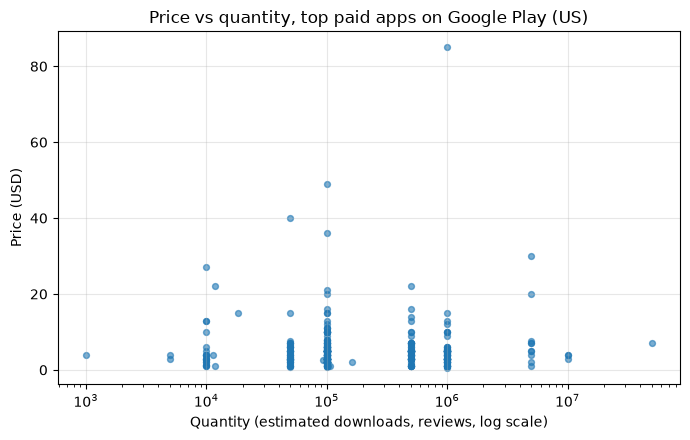

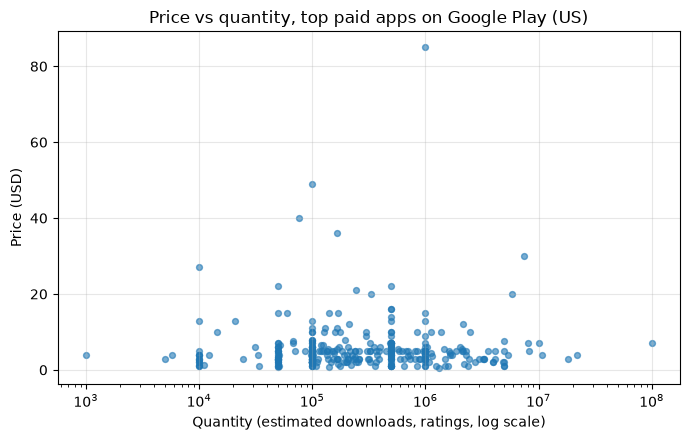

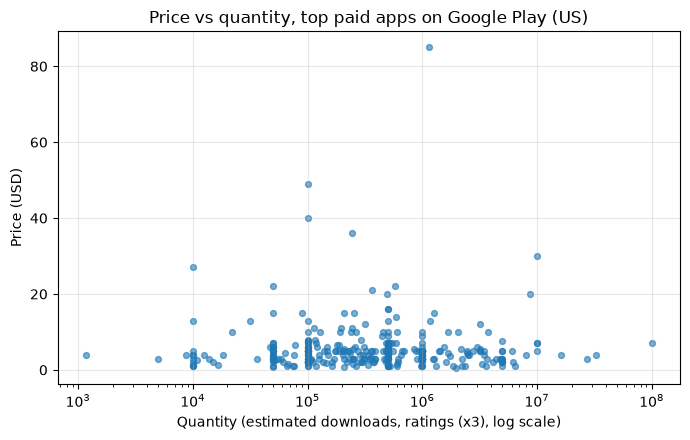

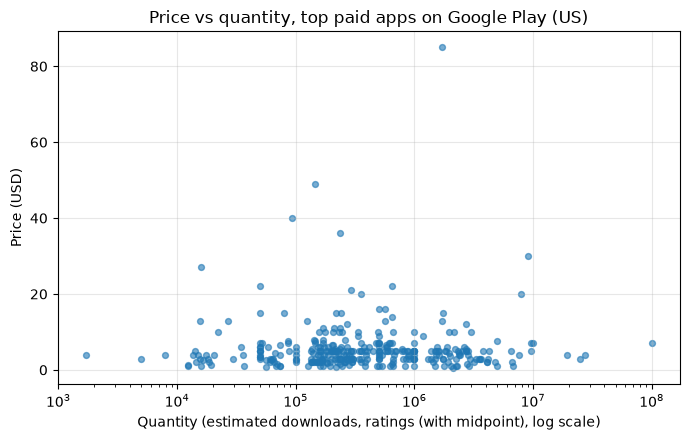

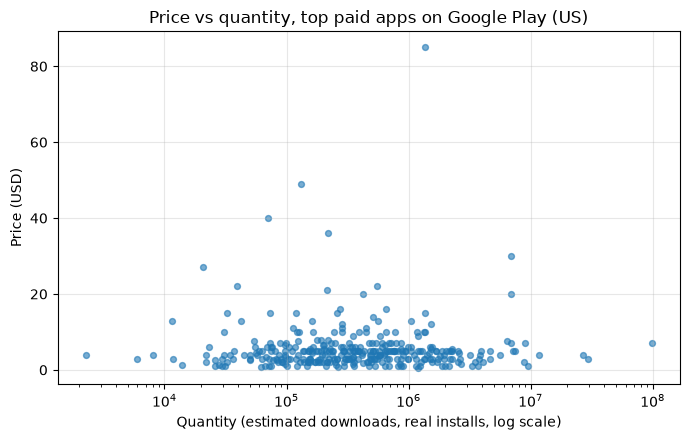

In [52]:
#produce a scatter plot of price vs quantity (downloads) for the top paid apps on Google Play (US)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity"], final["prices"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_xlabel("Quantity (estimated downloads, reviews, log scale)")
ax.set_ylabel("Price (USD)")
ax.set_title("Price vs quantity, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/price_quantity.png", dpi=300)
plt.show()

#produce a scatter plot of price vs quantity (downloads) for the top paid apps on Google Play (US)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity2"], final["prices"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_xlabel("Quantity (estimated downloads, ratings, log scale)")
ax.set_ylabel("Price (USD)")
ax.set_title("Price vs quantity, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/price_quantity_2.png", dpi=300)
plt.show()

#produce a scatter plot of price vs quantity (downloads) for the top paid apps on Google Play (US)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity3"], final["prices"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_xlabel("Quantity (estimated downloads, ratings (x3), log scale)")
ax.set_ylabel("Price (USD)")
ax.set_title("Price vs quantity, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/price_quantity_3.png", dpi=300)
plt.show()

#produce a scatter plot of price vs quantity (downloads) for the top paid apps on Google Play (US)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity4"], final["prices"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_xlabel("Quantity (estimated downloads, ratings (with midpoint), log scale)")
ax.set_ylabel("Price (USD)")
ax.set_title("Price vs quantity, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/price_quantity_4.png", dpi=300)
plt.show()

#produce a scatter plot of price vs quantity (downloads) for the top paid apps on Google Play (US)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["realInstalls"], final["prices"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_xlabel("Quantity (estimated downloads, real installs, log scale)")
ax.set_ylabel("Price (USD)")
ax.set_title("Price vs quantity, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/price_quantity_ri.png", dpi=300)
plt.show()

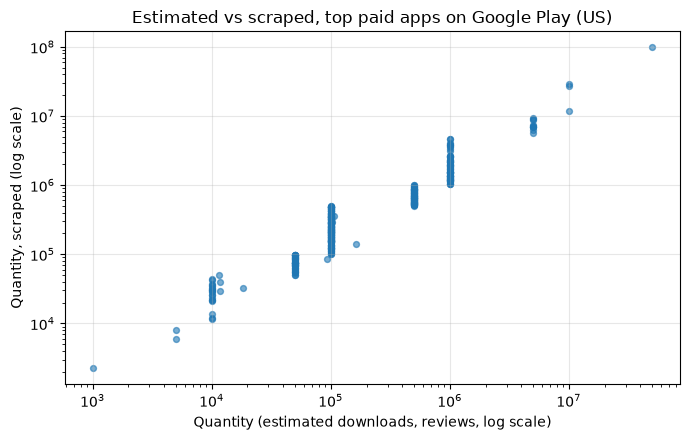

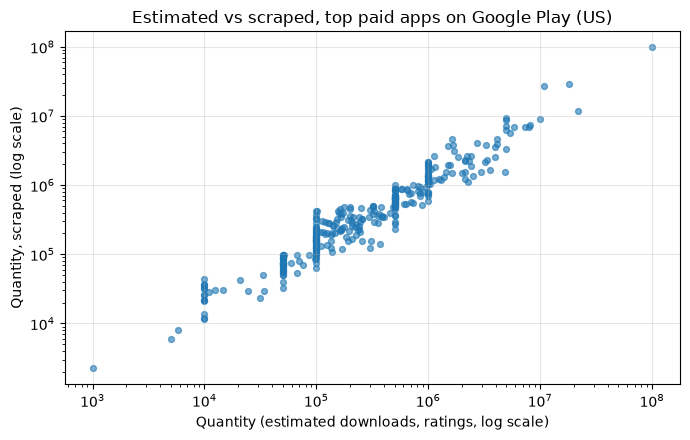

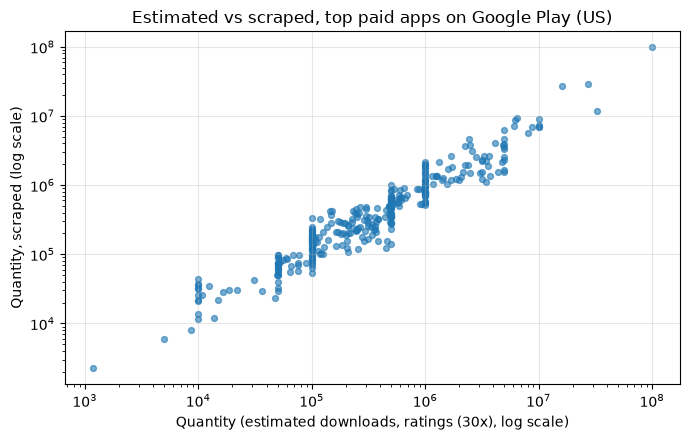

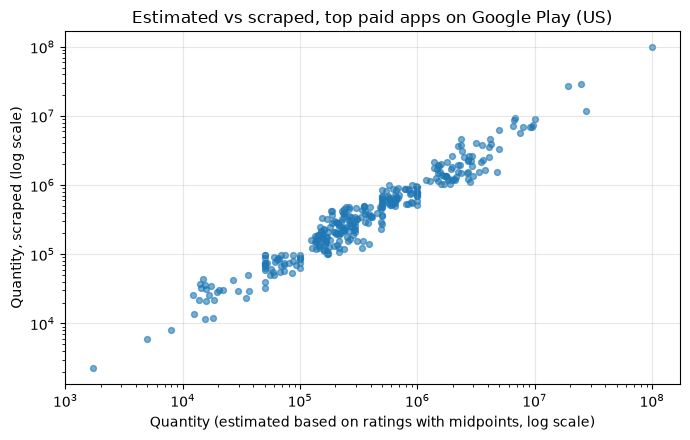

In [53]:
#produce a scatter plot of realInstalls vs estimated installs (based on ratings/reviews) for the top paid apps on Google Play (US)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity"], final["realInstalls"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_yscale("log")
ax.set_xlabel("Quantity (estimated downloads, reviews, log scale)")
ax.set_ylabel("Quantity, scraped (log scale)")
ax.set_title("Estimated vs scraped, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/estimated_scraped.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity2"], final["realInstalls"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_yscale("log")
ax.set_xlabel("Quantity (estimated downloads, ratings, log scale)")
ax.set_ylabel("Quantity, scraped (log scale)")
ax.set_title("Estimated vs scraped, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/estimated_scraped2.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity3"], final["realInstalls"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_yscale("log")
ax.set_xlabel("Quantity (estimated downloads, ratings (30x), log scale)")
ax.set_ylabel("Quantity, scraped (log scale)")
ax.set_title("Estimated vs scraped, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/estimated_scraped3.png", dpi=300)
plt.show()


fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(final["quantity4"], final["realInstalls"], s=18, alpha=0.6)
ax.set_xscale("log")   # quantity spans 1,000 to 50 million
ax.set_yscale("log")
ax.set_xlabel("Quantity (estimated based on ratings with midpoints, log scale)")
ax.set_ylabel("Quantity, scraped (log scale)")
ax.set_title("Estimated vs scraped, top paid apps on Google Play (US)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("output/estimated_scraped4.png", dpi=300)
plt.show()